**Eye-Tracking & Neurocognitive Intelligence | Eye-Tracking Foundations & Signal Analysis | Presented by: Reza Saadatyar (2026)**

**02 | Gap-Aware Gaze Preprocessing and Velocity**

![Gap-aware gaze preprocessing with measured source evidence and provisional motion representation](../../images/02_gap_aware_gaze_preprocessing.svg)

**Objective:** Prepare an offline, gap-respecting gaze representation and adjacent-sample angular velocity for later event analysis, while preserving original sample provenance.

**Recorded original-data execution:** GazeBase v2.0, Round 1, Session 1; ten participants, four tasks each (FXS, HSS, RAN and TEX), **40 recordings and 2,778,008 processed sample rows**, matching Notebook 01. The source CSV was approximately **511.9 MiB** and the saved processed CSV approximately **623.4 MiB** in the committed run.

**Scientific method:** A centred five-sample rolling median is calculated within contiguous valid gaze runs, with a 5-ms maximum intersample time gap; motion speed uses smoothed coordinates and actual positive time differences in degrees of visual angle per second (dva/s). The source x/y measurements are retained; missing gaze is not reconstructed.

**Quality finding requiring review:** The recorded maximum computed speeds include approximately **27,819 dva/s** (`S_1007_S1_TEX`) and **24,946 dva/s** (`S_1002_S1_TEX`). These are *unverified extreme measurements*, not established physiological saccade velocities. The added diagnostic section inspects their adjacent sample values, validity codes and time steps without changing the preprocessing, selecting a threshold or removing data.

**Evidence status:** The original 40-record preprocessing and velocity plot have executed. The newly added peak-window diagnostic is **pending execution**; the SVG distinguishes source observations from methodological schematics.


**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/Eye-Tracking-Neurocognitive-Intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/Eye-Tracking-Neurocognitive-Intelligence


**01. Imports and Research Environment**

In [ ]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("eye_tracking_foundations")

# ----------------- 2. Scientific Computing and Data Analysis -----------------
import pandas as pd

# ------------------- 3. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure
from core.output_download import download_outputs_from_colab

# ------------------------ 4. Study Research Utilities ------------------------
from core.stage_outputs import ensure_stage_inputs
from gaze_diagnostics import inspect_velocity_peaks
from gaze_streaming import preprocess_stage_file, validate_notebook_01_inputs

# --------------------- 5. Output and Presentation Setup ----------------------
output_dir = root / "eye_tracking_foundations" / "output"
output_dir.mkdir(parents=True, exist_ok=True)
plot_style(
    font_family="DejaVu Sans", title_size=12.5,
    title_weight="normal", label_size=11.5,
    label_weight="normal", tick_size=11,
    legend_size=10, figure_dpi=100, figure_size=(10, 4),
)
print("Current outputs:", output_dir)


Repository updated.
Current outputs: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_tracking_foundations/output


**02. Recover Notebook 01 Current Inputs**

Reuse the three named Notebook 01 outputs: `01_gaze_samples.csv` (the full sample-level table), `01_source_manifest.csv` (selected record identities) and `01_quality_by_record.csv` (original per-record sample counts). The manifest and quality table must describe exactly the same source recordings.

In the existing Colab runtime, reuse these files from `eye_tracking_foundations/output/`. In a new runtime, upload the current `eye_tracking_foundations_Notebook_01_Outputs.zip` to `/content/`; the Notebook-input helper restores the named files without loading the large CSV entirely into memory. Subsequent processing reads the source CSV in bounded chunks but applies the fixed method to **one complete recording at a time**. No Notebook 01 recomputation is needed.


In [3]:
# ================== 02. Recover Notebook 01 Current Inputs ===================

# ------------------------ 1. Verify Upstream Outputs -------------------------
ensure_stage_inputs(
    output_dir, 1, (
        "01_gaze_samples.csv",
        "01_source_manifest.csv",
        "01_quality_by_record.csv",
    )
)
source_csv = output_dir / "01_gaze_samples.csv"
manifest = pd.read_csv(
    output_dir / "01_source_manifest.csv",
    dtype={"record_id": str, "participant_id": str}, low_memory=False,
)
quality_source = pd.read_csv(
    output_dir / "01_quality_by_record.csv",
    dtype={"record_id": str, "participant_id": str}, low_memory=False,
)

# ------------------- 2. Match Source Identities and Sizes --------------------
expected_record_counts = validate_notebook_01_inputs(manifest, quality_source)
expected_records = set(expected_record_counts)
print("Notebook 01 participants:", manifest["participant_id"].nunique())
print("Notebook 01 task recordings:", len(expected_records))
print("Notebook 01 source sample rows:", sum(expected_record_counts.values()))
print("Input CSV (MiB):", round(source_csv.stat().st_size / 1024**2, 1))
display(manifest[["record_id", "participant_id", "task"]].head(8))


Notebook 01 participants: 10
Notebook 01 task recordings: 40
Notebook 01 source sample rows: 2778008
Input CSV (MiB): 511.9


,record_id,participant_id,task
0,S_1001_S1_FXS,001,FXS
1,S_1001_S1_HSS,001,HSS
2,S_1001_S1_RAN,001,RAN
3,S_1001_S1_TEX,001,TEX
4,S_1002_S1_FXS,002,FXS
5,S_1002_S1_HSS,002,HSS
6,S_1002_S1_RAN,002,RAN
7,S_1002_S1_TEX,002,TEX


**03. Apply Gap-Respecting Smoothing**

Use a centred **five-sample rolling median** separately within uninterrupted valid gaze runs. Eligible samples require `val = 0`, finite `x/y`, increasing timestamp `n`, and adjacent time intervals of **at most 5 ms**. Invalid samples, reversed or duplicate timestamps and longer gaps break continuity; no interpolation or blink reconstruction occurs. This **5-ms preprocessing rule** must not be confused with Notebook 01's descriptive *three-times-median* large-gap audit.

Preserve original gaze coordinates and source fields alongside `x_smooth`, `y_smooth`, `segment_id` and `velocity_dva_s`. The processing helper checks record identity and sample counts against the two compact Notebook 01 tables before accepting a complete output. Five samples and 5 ms are **provisional analysis settings**, not thresholds tuned to vendor labels.


In [4]:
# ==================== 03. Apply Gap-Respecting Smoothing =====================

# ---------------------- 1. Declare Scientific Settings -----------------------
SMOOTHING_SAMPLES = 5
MAX_GAP_MS = 5.0
READ_CHUNK_ROWS = 80_000

# ------------------ 2. Stream Full Records and Save Output -------------------
segments, example_trace = preprocess_stage_file(
    source_csv,
    output_dir / "02_preprocessed_samples.csv",
    smoothing_samples=SMOOTHING_SAMPLES,
    max_gap_ms=MAX_GAP_MS,
    chunksize=READ_CHUNK_ROWS,
    expected_records=expected_records,
    expected_record_counts=expected_record_counts,
)
if len(segments) != len(manifest):
    raise ValueError("Preprocessing record count differs from the source manifest.")
if int(segments["n_samples"].sum()) <= 0:
    raise ValueError("No source samples were processed.")
print("Prepared records:", len(segments))
print("Prepared samples:", int(segments["n_samples"].sum()))


Prepared records: 40
Prepared samples: 2778008


**04. Inspect Segments and Velocity**

Calculate velocity from smoothed gaze displacement between consecutive eligible samples divided by their positive elapsed time in seconds. The result is expressed in dva/s. Velocity at the first sample of each valid run, during invalid observations and across temporal gaps remains undefined rather than being set to zero.

The committed original-data execution retained **2,778,008 rows across 40 task recordings and 10 participants**, and its CSV was **623.4 MiB**. The per-record summary includes valid samples, the number of uninterrupted valid runs, median velocity and observed maximum velocity. These maxima are descriptive computed values, not independently verified eye-movement events.

Several very high maxima, particularly in the reading task, require targeted inspection before interpreting I-VT classifications. In particular, maximum velocity can be affected by sudden changes in x/y, timing intervals and still-valid source flags. The diagnostic immediately below checks these factors without retrospectively adjusting the five-sample median or 5-ms continuity rule.


In [5]:
# ===================== 04. Inspect Segments and Velocity =====================

# ------------------------- 1. Persist Record Summary -------------------------
segments.to_csv(output_dir / "02_preprocessing_summary.csv", index=False)
display(segments)

# ----------------------- 2. Check Observable Coverage ------------------------
print("Participants represented:", segments["participant_id"].nunique())
print("Source records represented:", segments["record_id"].nunique())
print("Prepared output (MiB):", round(
    (output_dir / "02_preprocessed_samples.csv").stat().st_size / 1024**2, 1
))


,record_id,participant_id,task,n_samples,n_valid,n_segments,median_velocity_dva_s,max_velocity_dva_s
0,S_1001_S1_FXS,001,FXS,15077,14588,5,5.879000,1056.465514
1,S_1001_S1_HSS,001,HSS,101299,100933,6,8.014674,1297.211310
2,S_1001_S1_RAN,001,RAN,101204,99866,17,6.241999,16217.296917
3,S_1001_S1_TEX,001,TEX,60233,58228,18,6.573593,19286.196359
4,S_1002_S1_FXS,002,FXS,15074,14597,4,6.585224,1426.570584
5,S_1002_S1_HSS,002,HSS,101313,100397,10,8.704074,5061.586183
6,S_1002_S1_RAN,002,RAN,101299,100374,9,8.662000,14102.246335
7,S_1002_S1_TEX,002,TEX,60237,59367,8,8.781000,24946.456368
8,S_1003_S1_FXS,003,FXS,15074,14872,2,2.946000,1177.772002
9,S_1003_S1_HSS,003,HSS,101332,101071,2,5.893000,1337.353361


Participants represented: 10
Source records represented: 40
Prepared output (MiB): 623.4


**04A. Inspect Extreme Velocity Windows (Diagnostic Only)**

The recorded summary includes maximum computed speeds of roughly **27,819 dva/s** in `S_1007_S1_TEX` and **24,946 dva/s** in `S_1002_S1_TEX`. These are unusual estimates requiring source-level review; an extreme calculated speed is **not automatically evidence of a physiological saccade, a malfunction or a faulty algorithm**.

Select the **three recordings with the highest observed per-record maxima**. For each one, locate its peak in `02_preprocessed_samples.csv` and inspect up to **60 samples before and after** the peak. Record the current and preceding `val` flags, valid-run membership, actual time step `Δt` in milliseconds, raw gaze displacement and smoothed gaze displacement. Reconstruct the reported velocity numerically from the adjacent smoothed samples and timestamp difference.

Save `02_velocity_extreme_review.csv` and `02_velocity_extreme_trace.png`. The review figure displays the original and smoothed x/y signals, source `val`, adjacent `Δt` and computed speed around each peak. Its velocity axis uses a labelled **symmetric-logarithmic scale** to show both smaller values and extreme peaks.

**Decision boundary:** This is descriptive quality assurance. It **does not flag or delete samples**, change smoothing or event thresholds, redefine eligible runs, alter `02_preprocessed_samples.csv`, or certify the peaks as physiological. Notebook 03 should be interpreted cautiously until these windows have been inspected.


,record_id,peak_sample_index,peak_velocity_dva_s,previous_val,peak_val,delta_t_ms,raw_displacement_dva,smoothed_displacement_dva,reconstructed_velocity_dva_s
0,S_1007_S1_TEX,55528,27819.098468,0,0,1.0,27.819098,27.819098,27819.098468
1,S_1002_S1_TEX,25482,24946.456368,0,0,1.0,25.147235,24.946456,24946.456368
2,S_1001_S1_TEX,33999,19286.196359,0,0,1.0,19.315149,19.286196,19286.196359


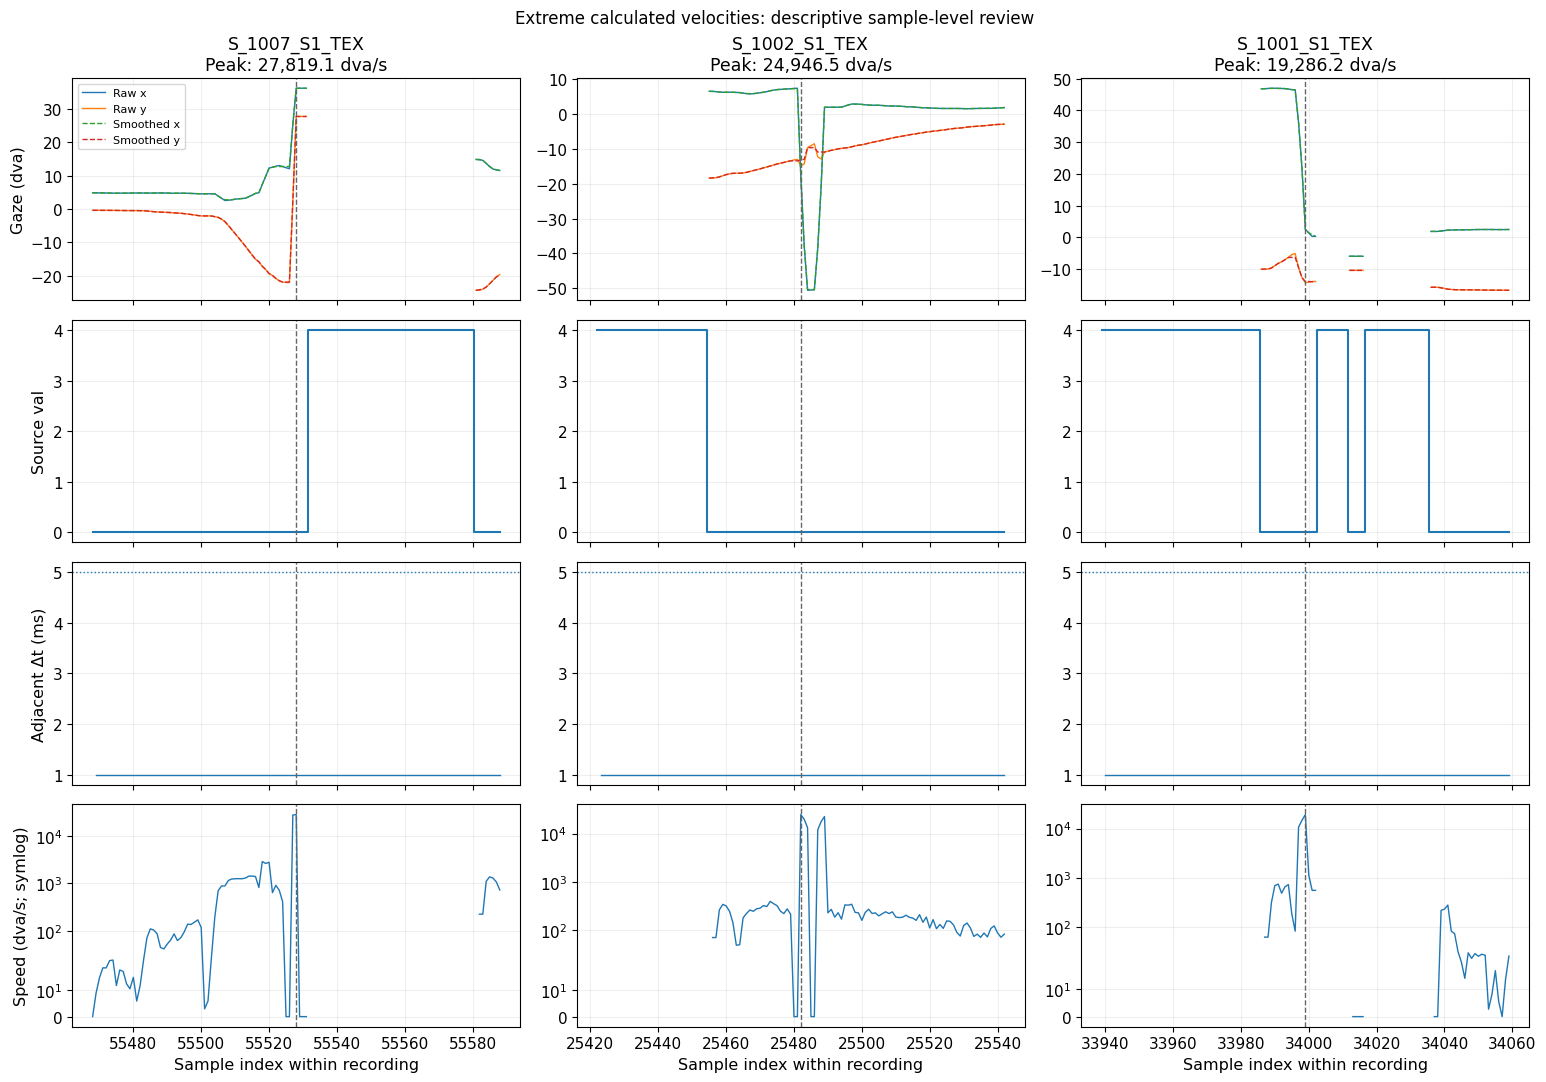

In [ ]:
# =================== 04A. Inspect Extreme Velocity Windows ===================

# ---------------------- 1. Select Highest Record Maxima ----------------------
peak_review, peak_windows = inspect_velocity_peaks(
    output_dir / "02_preprocessed_samples.csv",
    segments,
    top_records=3,
    half_window_samples=60,
    chunksize=READ_CHUNK_ROWS,
)
peak_review.to_csv(output_dir / "02_velocity_extreme_review.csv", index=False)
display(peak_review[[
    "record_id", "peak_sample_index", "peak_velocity_dva_s",
    "previous_val", "peak_val", "delta_t_ms",
    "raw_displacement_dva", "smoothed_displacement_dva",
    "reconstructed_velocity_dva_s",
]])

# ------------ 2. Plot Original Signals and Neighbouring Metadata -------------
fig, axes = plt.subplots(
    4, len(peak_review), figsize=(5.2 * len(peak_review), 11),
    sharex="col", squeeze=False,
)
for col, (_, peak) in enumerate(peak_review.iterrows()):
    rid = str(peak["record_id"])
    window = peak_windows.loc[
        peak_windows["record_id"].eq(rid)
    ].sort_values("sample_index")
    index = window["sample_index"]
    peak_index = int(peak["peak_sample_index"])

    # The raw x/y samples and their smoothed representation are both shown.
    axes[0, col].plot(index, window["x"], lw=1, label="Raw x")
    axes[0, col].plot(index, window["y"], lw=1, label="Raw y")
    axes[0, col].plot(
        index, window["x_smooth"], lw=1, ls="--", label="Smoothed x"
    )
    axes[0, col].plot(
        index, window["y_smooth"], lw=1, ls="--", label="Smoothed y"
    )
    axes[0, col].set_title(
        f"{rid}\nPeak: {peak['peak_velocity_dva_s']:,.1f} dva/s"
    )

    # val=0 indicates a nominally valid source sample.
    axes[1, col].step(index, window["val"], where="mid")
    axes[2, col].plot(index, window["n"].diff(), lw=1)
    axes[2, col].axhline(
        MAX_GAP_MS, ls=":", lw=1, label="5-ms continuity limit"
    )
    axes[3, col].plot(index, window["velocity_dva_s"], lw=1)
    axes[3, col].set_yscale("symlog", linthresh=20)
    axes[3, col].set_xlabel("Sample index within recording")

    for row in range(4):
        axes[row, col].axvline(peak_index, color="0.4", ls="--", lw=1)
        axes[row, col].grid(alpha=0.2)

axes[0, 0].set_ylabel("Gaze (dva)")
axes[1, 0].set_ylabel("Source val")
axes[2, 0].set_ylabel("Adjacent Δt (ms)")
axes[3, 0].set_ylabel("Speed (dva/s; symlog)")
axes[0, 0].legend(loc="best", fontsize=8)
fig.suptitle("Extreme calculated velocities: descriptive sample-level review")
fig.tight_layout()
save_figure(fig, output_dir / "02_velocity_extreme_trace.png")
plt.show()


**05. Compare Raw and Processed Gaze**

The recorded Notebook 02 execution includes a raw-versus-smoothed horizontal gaze trace and derived velocity for the first 3,000 samples of one recording. Source coordinates are kept distinct from the filtered representation; missing boundary velocities remain undefined.

The original introduction SVG contains a measured short *raw-source* gaze excerpt and method diagrams. The new `02_velocity_extreme_trace.png` (Section 04A) is a separate empirical review around the largest calculated velocities, rather than a substitute for the general trace `02_velocity_profile.png`. Neither image by itself demonstrates better event-detection performance.


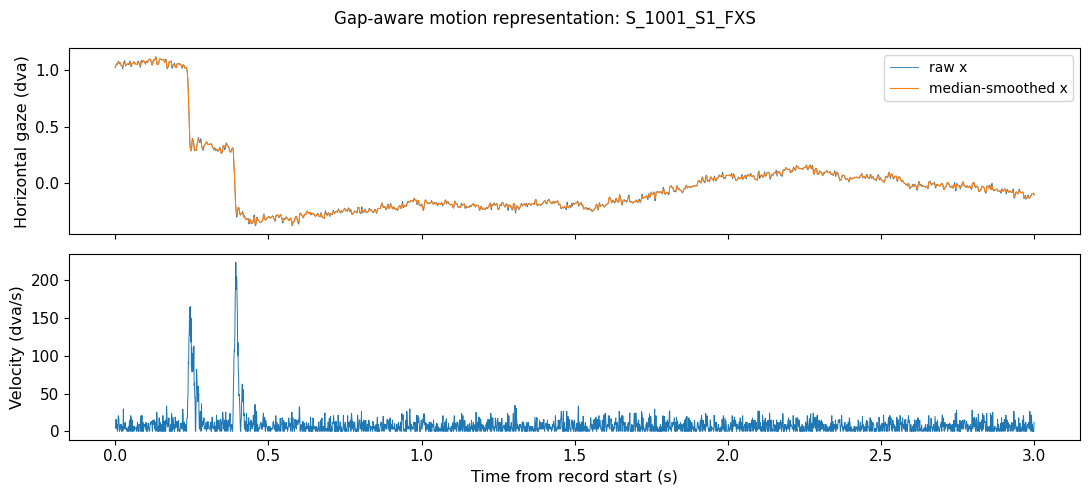

In [7]:
# ==================== 05. Compare Raw and Processed Gaze =====================

record_id = str(example_trace.record_id.iloc[0])
part = example_trace
fig, axes = plt.subplots(2,1, figsize=(11,5), sharex=True)
axes[0].plot(part.time_s, part.x, lw=0.6, label="raw x")
axes[0].plot(part.time_s, part.x_smooth, lw=0.8, label="median-smoothed x")
axes[0].set_ylabel("Horizontal gaze (dva)")
axes[0].legend()
axes[1].plot(part.time_s, part.velocity_dva_s, lw=0.7)
axes[1].set_ylabel("Velocity (dva/s)")
axes[1].set_xlabel("Time from record start (s)")
fig.suptitle(f"Gap-aware motion representation: {record_id}")
fig.tight_layout()
save_figure(fig, output_dir / "02_velocity_profile.png")
plt.show()


**06. Export Reusable Numerical Inputs**

Notebook 02 now owns five current outputs:

- `02_preprocessed_samples.csv`: all source-aligned gaze rows and derived within-run representation, used by Notebook 03.
- `02_preprocessing_summary.csv`: compact record-level coverage, valid-run and velocity statistics.
- `02_velocity_profile.png`: general raw-versus-smoothed trace and speed.
- `02_velocity_extreme_review.csv`: adjacent-sample checks for the three highest recorded speed maxima.
- `02_velocity_extreme_trace.png`: observed x/y, source validity, time intervals and speed around those peaks.

The additional two diagnostic files are **not inputs required by Notebook 03**; they exist to qualify interpretation of the same unchanged prepared sample CSV. The unchanged output-download helper packages all files with the `02_` prefix for private reuse. Do not commit large CSVs or the output ZIP to GitHub. Inspect the new diagnostic before moving to event detection.


In [8]:
# =================== 06. Export Reusable Numerical Inputs ====================

print("Missing velocities at segment starts remain NaN.")
print("Current motion representation:", output_dir / "02_preprocessed_samples.csv")
download_outputs_from_colab("eye_tracking_foundations/output", "02")


Missing velocities at segment starts remain NaN.
Current motion representation: /content/Eye-Tracking-Neurocognitive-Intelligence/eye_tracking_foundations/output/02_preprocessed_samples.csv
------------------------------------------------------------------------
Notebook 02
Files packaged: 5
  + 02_preprocessed_samples.csv
  + 02_preprocessing_summary.csv
  + 02_velocity_extreme_review.csv
  + 02_velocity_extreme_trace.png
  + 02_velocity_profile.png
Download ZIP from Colab Contents: /content/eye_tracking_foundations_Notebook_02_Outputs.zip
